In [177]:
import networkx as nx
import matplotlib.pyplot as plt
import json

In [178]:
def loadJson(file:str):
    with open(file, mode='rt') as f:
        return json.loads(f.read())

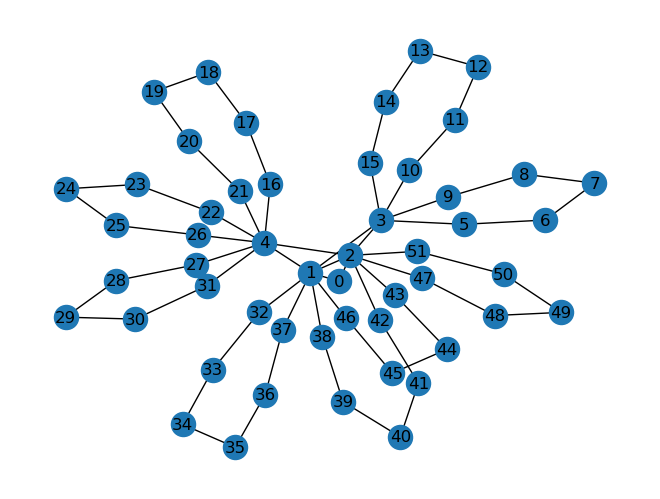

In [179]:
# T1-TOPO

f1_node_data = loadJson("./model_files/T1_files/F1_51_CRs_nodes_HC.json")
r1_node_data = loadJson("./model_files/T1_files/R1_51_CRs_nodes_HC.json")
link_data = loadJson("./model_files/T1_files/51_CRs_links_HC_edited.json")

G2 = nx.Graph()
G2.add_nodes_from([
    (int(n[5:]), {"cpu_cap": f1_node_data['nodes'][n]['CPU'], 'is_ru': f1_node_data['nodes'][n]['RU']})
    for n in f1_node_data['nodes']
])
G2.add_edges_from( [
    (int(link_data['links'][l]['source']['node'][1:]), int(link_data['links'][l]['destination']['node'][1:]), {"linkCapacity": link_data['links'][l]['linkCapacity'], "linkDelay": link_data['links'][l]['LinkDelay']})
    for l in link_data['links']
])

nx.draw_kamada_kawai(G2, with_labels=True)

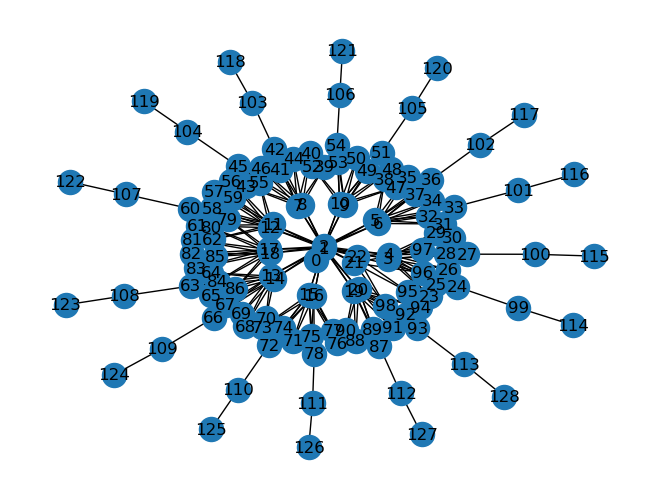

In [180]:
# T2-TOPO

f1_node_data = loadJson("./model_files/T2_files/F1_128_CRs_nodes_HC.json")
r1_node_data = loadJson("./model_files/T2_files/R1_128_CRs_nodes_HC.json")
link_data = loadJson("./model_files/T2_files/128_CRs_links_HC.json")

G2 = nx.Graph()
G2.add_nodes_from([
    (int(n['nodeNumber']), {"cpu_cap": n['cpu'], "n_links": n['links'], 'is_ru': n['RU'], "type": n['nodeType']})
    for n in f1_node_data['nodes']
])
G2.add_edges_from( [
    (int(l['fromNode']), int(l['toNode']), {"linkCapacity": l['capacity'], "linkDelay": l['delay']})
    for l in link_data['links']
])

nx.draw_kamada_kawai(G2, with_labels=True)